# Predicción de resultados de la Liga MX con machine learning

**Autora:** Sharon Xolocotzi Castillo · Licenciatura en Ciencia de Datos, ESCOM-IPN

**Pregunta:** con la información disponible antes de cada partido (forma reciente de cada equipo y condición de local), ¿qué tan bien se puede predecir si gana el local, hay empate o gana el visitante?

**Enfoque:** clasificación multiclase (H / D / A). Las variables se construyen con SQL usando funciones de ventana, los modelos se ajustan con validación cruzada temporal y el resultado se compara contra dos referencias: un modelo que siempre elige "gana el local" y las probabilidades implícitas en los momios de cierre.

| Etapa | Contenido |
|---|---|
| 1 | Carga y limpieza de datos |
| 2 | Análisis exploratorio |
| 3 | Ingeniería de variables con SQL |
| 4 | División temporal y modelos de referencia |
| 5 | Entrenamiento con validación cruzada temporal |
| 6 | Evaluación en temporadas no vistas |
| 7 | Conclusiones y limitaciones |

## 0. Configuración

In [2]:
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEMILLA = 42

# Raíz del repositorio (funciona si el notebook se abre desde /notebooks o desde la raíz)
RAIZ = Path.cwd() if (Path.cwd() / "sql").exists() else Path.cwd().parent
RUTA_DATOS = RAIZ / "data" / "raw" / "MEX.csv"
RUTA_SQL = RAIZ / "sql" / "variables_forma_reciente.sql"
RUTA_FIGURAS = RAIZ / "reports" / "figures"
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

URL_DATOS = "https://www.football-data.co.uk/new/MEX.csv"
CLASES = ["H", "D", "A"]  # gana local, empate, gana visitante

## 1. Carga y limpieza de datos

Fuente: [football-data.co.uk](https://www.football-data.co.uk/mexico.php) (archivo `MEX.csv`, de uso libre). Cada fila es un partido con fecha, equipos, marcador final, resultado y momios de cierre de varias casas de apuestas.

In [3]:
if RUTA_DATOS.exists():
    crudo = pd.read_csv(RUTA_DATOS)
    print(f"Datos leídos desde {RUTA_DATOS}")
else:
    crudo = pd.read_csv(URL_DATOS)
    RUTA_DATOS.parent.mkdir(parents=True, exist_ok=True)
    crudo.to_csv(RUTA_DATOS, index=False)
    print(f"Datos descargados de {URL_DATOS}")

print(crudo.shape)
crudo.head()

Datos leídos desde /home/claude/scratch/real/data/raw/MEX.csv
(4799, 32)


,Country,League,Season,Date,Time,Home,Away,HG,AG,Res,...,B365CH,B365CD,B365CA,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,Mexico,Liga MX,2012/2013,21/07/2012,01:30,Chiapas,Tigres UANL,0,4,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Mexico,Liga MX,2012/2013,21/07/2012,03:30,Club Tijuana,Puebla,2,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Mexico,Liga MX,2012/2013,21/07/2012,23:00,Cruz Azul,Monarcas,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Mexico,Liga MX,2012/2013,21/07/2012,23:00,Queretaro,Club Leon,0,2,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Mexico,Liga MX,2012/2013,22/07/2012,01:00,Monterrey,Club America,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 4799 entries, 0 to 4798
Data columns (total 32 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Country      4799 non-null   str    
 1   League       4799 non-null   str    
 2   Season       4799 non-null   str    
 3   Date         4799 non-null   str    
 4   Time         4799 non-null   str    
 5   Home         4799 non-null   str    
 6   Away         4799 non-null   str    
 7   HG           4799 non-null   int64  
 8   AG           4799 non-null   int64  
 9   Res          4799 non-null   str    
 10  PSCH         4437 non-null   float64
 11  PSCD         4437 non-null   float64
 12  PSCA         4437 non-null   float64
 13  MaxCH        4799 non-null   float64
 14  MaxCD        4799 non-null   float64
 15  MaxCA        4799 non-null   float64
 16  AvgCH        4799 non-null   float64
 17  AvgCD        4799 non-null   float64
 18  AvgCA        4799 non-null   float64
 19  BFECH        779 

Se renombran las columnas principales al español y se identifican las columnas de momios de cierre. Se usa el **promedio del mercado** (`AvgCH/AvgCD/AvgCA`) porque está completo en todas las temporadas; los momios de Pinnacle (`PSCH/PSCD/PSCA`) dejan de registrarse a partir de 2025/2026.

In [5]:
renombrar = {
    "Country": "pais", "League": "liga", "Season": "temporada",
    "Date": "fecha", "Time": "hora", "Home": "local", "Away": "visitante",
    "HG": "goles_local", "AG": "goles_visitante", "Res": "resultado",
}
df = crudo.rename(columns=renombrar).copy()

# Momios: primer trío disponible en orden de preferencia
candidatos_momios = [("AvgCH", "AvgCD", "AvgCA"), ("PSCH", "PSCD", "PSCA"),
                     ("B365CH", "B365CD", "B365CA"), ("PSH", "PSD", "PSA"),
                     ("AvgH", "AvgD", "AvgA")]
COLS_MOMIOS = next((c for c in candidatos_momios if set(c).issubset(df.columns)), None)
print("Momios usados como referencia:", COLS_MOMIOS)

if "liga" in df.columns:
    print("Ligas en el archivo:", df["liga"].unique())

Momios usados como referencia: ('AvgCH', 'AvgCD', 'AvgCA')
Ligas en el archivo: <StringArray>
['Liga MX']
Length: 1, dtype: str


In [6]:
# Tipos de dato
df["fecha"] = pd.to_datetime(df["fecha"], dayfirst=True, errors="coerce")
df["goles_local"] = pd.to_numeric(df["goles_local"], errors="coerce")
df["goles_visitante"] = pd.to_numeric(df["goles_visitante"], errors="coerce")

n_inicial = len(df)
df = df.dropna(subset=["fecha", "local", "visitante", "goles_local", "goles_visitante", "resultado"])
df = df.drop_duplicates(subset=["fecha", "local", "visitante"])

# Consistencia: el resultado debe coincidir con el marcador
resultado_calc = np.select(
    [df["goles_local"] > df["goles_visitante"], df["goles_local"] < df["goles_visitante"]],
    ["H", "A"], default="D")
inconsistentes = (resultado_calc != df["resultado"]).sum()
print(f"Filas eliminadas por nulos o duplicados: {n_inicial - len(df)}")
print(f"Resultados inconsistentes con el marcador: {inconsistentes}")

df = df.sort_values(["fecha", "local"]).reset_index(drop=True)
df["id_partido"] = np.arange(len(df))
print(f"Partidos válidos: {len(df)} | del {df['fecha'].min():%d/%m/%Y} al {df['fecha'].max():%d/%m/%Y}")

Filas eliminadas por nulos o duplicados: 0
Resultados inconsistentes con el marcador: 0
Partidos válidos: 4799 | del 21/07/2012 al 14/11/2026


## 2. Análisis exploratorio

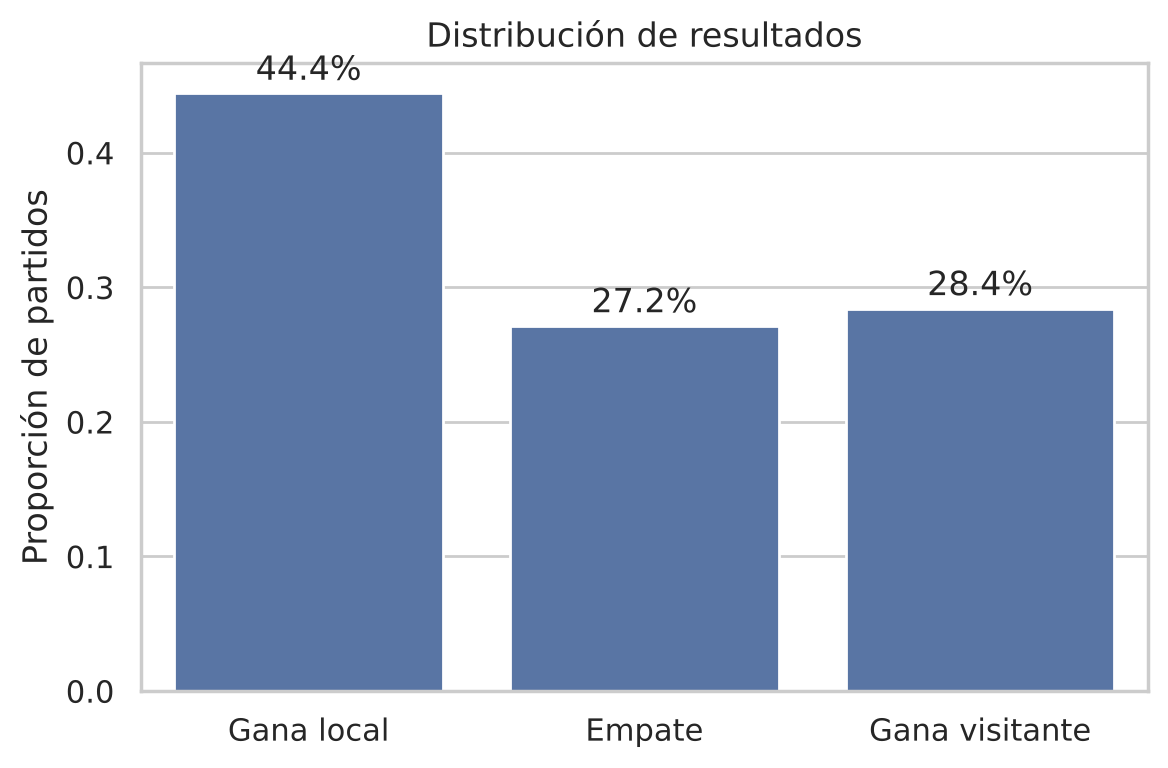

In [7]:
dist = df["resultado"].value_counts(normalize=True).reindex(CLASES)
etiquetas = {"H": "Gana local", "D": "Empate", "A": "Gana visitante"}

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=[etiquetas[c] for c in CLASES], y=dist.values, ax=ax, color="#4C72B0")
for i, v in enumerate(dist.values):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
ax.set(title="Distribución de resultados", ylabel="Proporción de partidos", xlabel="")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "distribucion_resultados.png", dpi=150)
plt.show()

La ventaja de jugar en casa se ve directamente en la proporción de victorias locales. Ese porcentaje es justo lo que obtiene un modelo que **siempre** predice "gana el local", así que cualquier modelo útil tiene que superarlo.

In [8]:
por_temporada = (df.assign(goles_totales=df["goles_local"] + df["goles_visitante"])
                   .groupby("temporada")
                   .agg(partidos=("id_partido", "count"),
                        goles_por_partido=("goles_totales", "mean"),
                        pct_local=("resultado", lambda s: (s == "H").mean()),
                        pct_empate=("resultado", lambda s: (s == "D").mean())))
por_temporada.style.format({"goles_por_partido": "{:.2f}", "pct_local": "{:.1%}", "pct_empate": "{:.1%}"})

,partidos,goles_por_partido,pct_local,pct_empate
temporada,,,,
2012/2013,334,2.47,42.8%,28.4%
2013/2014,334,2.58,41.9%,32.0%
2014/2015,334,2.46,44.3%,29.6%
2015/2016,334,2.89,44.6%,24.6%
2016/2017,334,2.62,44.6%,29.3%
2017/2018,334,2.56,42.2%,29.0%
2018/2019,334,2.68,47.9%,24.6%
2019/2020,275,2.92,44.4%,24.0%
2020/2021,342,2.46,48.2%,25.1%


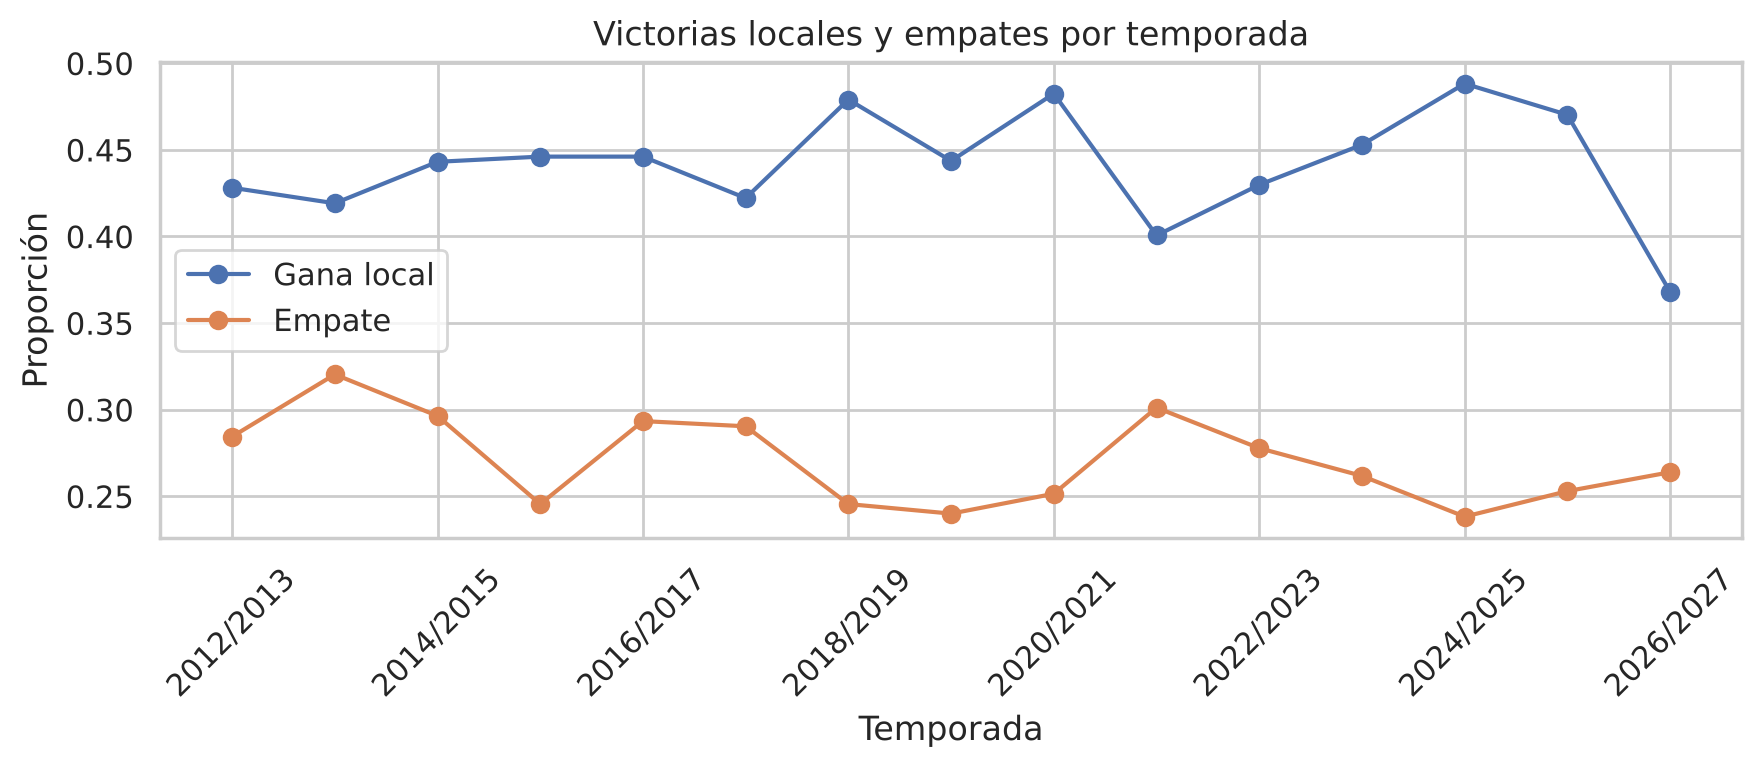

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
por_temporada[["pct_local", "pct_empate"]].plot(ax=ax, marker="o")
ax.set(title="Victorias locales y empates por temporada", ylabel="Proporción", xlabel="Temporada")
ax.legend(["Gana local", "Empate"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "tendencia_por_temporada.png", dpi=150)
plt.show()

## 3. Ingeniería de variables con SQL

Los datos se cargan a una base SQLite en memoria y las variables se calculan con la consulta `sql/variables_forma_reciente.sql`. Para cada partido se obtiene, por equipo, el promedio de **puntos**, **goles a favor** y **goles en contra** en sus 5 partidos anteriores, además de su forma jugando solo de local o solo de visitante.

La ventana `ROWS BETWEEN 5 PRECEDING AND 1 PRECEDING` deja fuera el partido que se quiere predecir. Así se evita la fuga de información: el modelo nunca ve datos del futuro.

In [10]:
conexion = sqlite3.connect(":memory:")
columnas_sql = ["id_partido", "fecha", "temporada", "local", "visitante",
                "goles_local", "goles_visitante", "resultado"]
(df[columnas_sql]
   .assign(fecha=df["fecha"].dt.strftime("%Y-%m-%d"))
   .to_sql("partidos", conexion, index=False))

consulta = RUTA_SQL.read_text(encoding="utf-8")
variables = pd.read_sql_query(consulta, conexion)
conexion.close()

variables["fecha"] = pd.to_datetime(variables["fecha"])
print(variables.shape)
variables.filter(like="ult5").head()

(4799, 18)


,local_pts_ult5,local_gf_ult5,local_gc_ult5,local_pts_ult5_en_casa,visita_pts_ult5,visita_gf_ult5,visita_gc_ult5,visita_pts_ult5_fuera
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Se agregan variables de diferencia (local menos visitante) y se descartan los partidos en los que algún equipo tiene menos de 3 partidos previos, porque su "forma reciente" todavía no es confiable (inicio del histórico o equipos recién ascendidos).

In [11]:
variables["dif_pts_ult5"] = variables["local_pts_ult5"] - variables["visita_pts_ult5"]
variables["dif_gf_ult5"] = variables["local_gf_ult5"] - variables["visita_gf_ult5"]
variables["dif_gc_ult5"] = variables["local_gc_ult5"] - variables["visita_gc_ult5"]

VARIABLES = [
    "local_pts_ult5", "local_gf_ult5", "local_gc_ult5", "local_pts_ult5_en_casa",
    "visita_pts_ult5", "visita_gf_ult5", "visita_gc_ult5", "visita_pts_ult5_fuera",
    "dif_pts_ult5", "dif_gf_ult5", "dif_gc_ult5",
]

modelo_df = variables[(variables["local_partidos_previos"] >= 3) &
                      (variables["visita_partidos_previos"] >= 3)].copy()
modelo_df[VARIABLES] = modelo_df[VARIABLES].fillna(modelo_df[VARIABLES].median())
print(f"Partidos para modelar: {len(modelo_df)}")
modelo_df[VARIABLES].describe().T.round(2)

Partidos para modelar: 4751


,count,mean,std,min,25%,50%,75%,max
local_pts_ult5,4751.0,1.34,0.61,0.0,0.8,1.4,1.8,3.0
local_gf_ult5,4751.0,1.32,0.55,0.0,1.0,1.2,1.6,3.8
local_gc_ult5,4751.0,1.35,0.55,0.0,1.0,1.4,1.6,3.8
local_pts_ult5_en_casa,4751.0,1.61,0.65,0.0,1.2,1.6,2.0,3.0
visita_pts_ult5,4751.0,1.39,0.63,0.0,1.0,1.4,1.8,3.0
visita_gf_ult5,4751.0,1.35,0.57,0.0,1.0,1.4,1.6,4.0
visita_gc_ult5,4751.0,1.32,0.55,0.0,1.0,1.2,1.6,3.8
visita_pts_ult5_fuera,4751.0,1.12,0.61,0.0,0.6,1.0,1.6,3.0
dif_pts_ult5,4751.0,-0.05,0.84,-3.0,-0.6,0.0,0.6,2.6
dif_gf_ult5,4751.0,-0.03,0.76,-2.6,-0.6,0.0,0.4,2.8


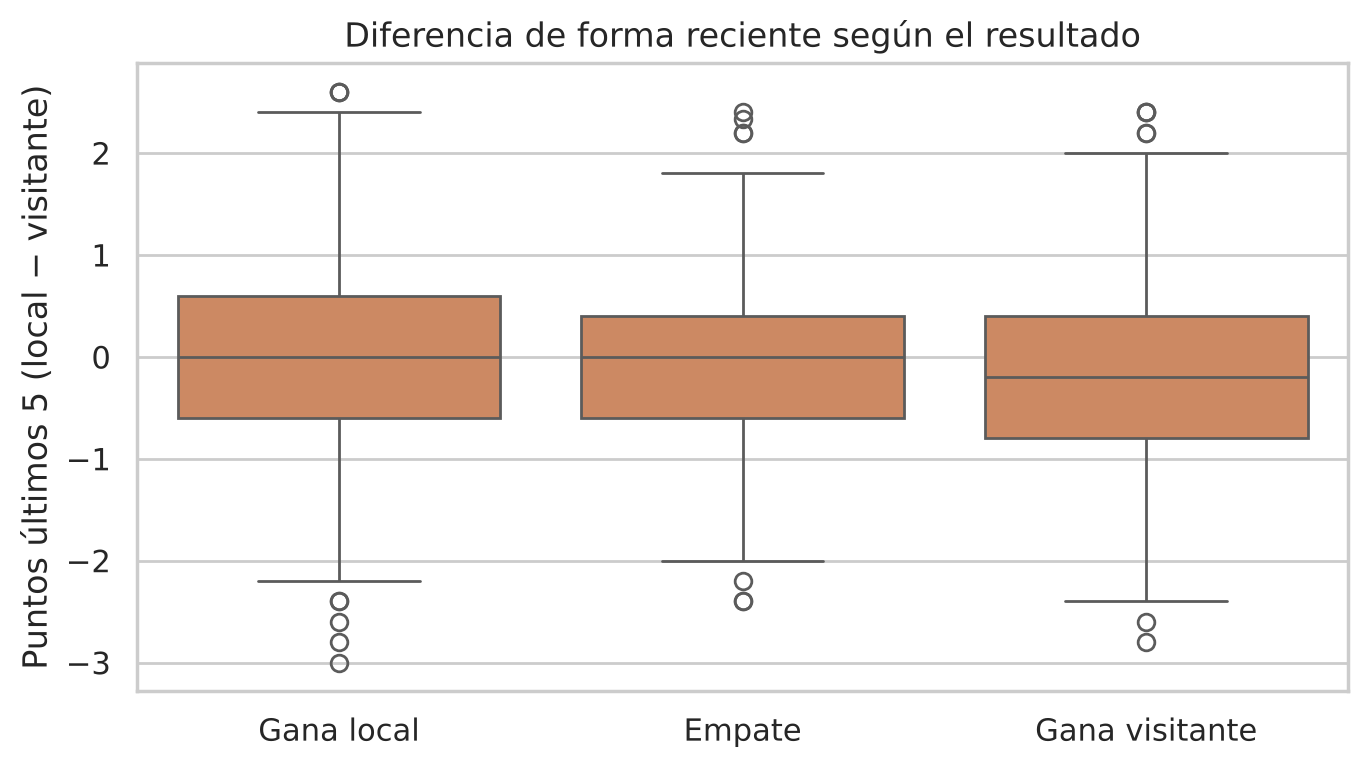

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=modelo_df, x="resultado", y="dif_pts_ult5", order=CLASES, ax=ax, color="#DD8452")
ax.set_xticklabels([etiquetas[c] for c in CLASES])
ax.set(title="Diferencia de forma reciente según el resultado",
       xlabel="", ylabel="Puntos últimos 5 (local − visitante)")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "forma_vs_resultado.png", dpi=150)
plt.show()

## 4. División temporal y modelos de referencia

En datos que ocurren en el tiempo no se debe hacer una división aleatoria: se entrenaría con partidos posteriores a los que se quieren predecir. Por eso las **dos últimas temporadas** se reservan como conjunto de prueba y todo lo anterior se usa para entrenar.

In [13]:
temporadas = sorted(modelo_df["temporada"].unique())
temporadas_prueba = temporadas[-2:]

entrenamiento = modelo_df[~modelo_df["temporada"].isin(temporadas_prueba)].sort_values("fecha")
prueba = modelo_df[modelo_df["temporada"].isin(temporadas_prueba)].sort_values("fecha")

X_train, y_train = entrenamiento[VARIABLES], entrenamiento["resultado"]
X_test, y_test = prueba[VARIABLES], prueba["resultado"]

print(f"Entrenamiento: {len(entrenamiento)} partidos ({temporadas[0]} a {temporadas[-3]})")
print(f"Prueba: {len(prueba)} partidos ({', '.join(map(str, temporadas_prueba))})")

Entrenamiento: 4271 partidos (2012/2013 a 2024/2025)
Prueba: 480 partidos (2025/2026, 2026/2027)


**Referencias para comparar:**

1. **Siempre local:** predice "gana el local" en todos los partidos; sus probabilidades son las frecuencias observadas en entrenamiento.
2. **Momios de cierre:** las probabilidades implícitas del mercado de apuestas (1 / momio, normalizadas para quitar el margen de la casa). Es una referencia muy exigente, porque resume toda la información pública disponible antes del partido.

In [14]:
resultados = []

def evaluar(nombre, y_real, proba):
    # proba: DataFrame con columnas H, D, A
    proba = proba[CLASES]
    pred = proba.idxmax(axis=1)
    resultados.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_real, pred),
        "f1_macro": f1_score(y_real, pred, average="macro"),
        # log_loss ordena las etiquetas alfabéticamente (A, D, H): las columnas deben ir en ese orden
        "log_loss": log_loss(y_real, proba[sorted(CLASES)].values, labels=sorted(CLASES)),
    })
    return pred

# 1) Siempre local
frecuencias = y_train.value_counts(normalize=True).reindex(CLASES)
proba_base = pd.DataFrame([frecuencias.values] * len(y_test), columns=CLASES, index=y_test.index)
proba_base["H"] += 1e-9  # desempate para que la predicción sea siempre H
evaluar("Referencia: siempre local", y_test, proba_base)

# 2) Momios de cierre
if COLS_MOMIOS:
    momios = crudo.loc[:, list(COLS_MOMIOS)].copy()
    momios.columns = CLASES
    momios = momios.apply(pd.to_numeric, errors="coerce")
    # Se recupera el id_partido uniendo por fecha y equipos con el df ya limpio
    llave = crudo.rename(columns=renombrar)[["fecha", "local", "visitante"]].copy()
    llave["fecha"] = pd.to_datetime(llave["fecha"], dayfirst=True, errors="coerce")
    momios = pd.concat([llave, momios[CLASES]], axis=1).merge(
        df[["fecha", "local", "visitante", "id_partido"]], on=["fecha", "local", "visitante"])
    implicitas = 1 / momios.set_index("id_partido")[CLASES]
    implicitas = implicitas.div(implicitas.sum(axis=1), axis=0)

    proba_momios = implicitas.reindex(prueba["id_partido"]).set_axis(y_test.index)
    disponibles = proba_momios.notna().all(axis=1)
    print(f"Partidos de prueba con momios: {disponibles.sum()} de {len(y_test)}")
    evaluar("Referencia: momios de cierre", y_test[disponibles], proba_momios[disponibles])

pd.DataFrame(resultados).round(3)

Partidos de prueba con momios: 480 de 480


,modelo,accuracy,f1_macro,log_loss
0,Referencia: siempre local,0.44,0.204,1.074
1,Referencia: momios de cierre,0.51,0.380,1.001


## 5. Entrenamiento con validación cruzada temporal

Se comparan tres modelos. Los hiperparámetros se eligen con `TimeSeriesSplit` (cada pliegue entrena con el pasado y valida con el periodo siguiente) y se optimiza el **log loss**, porque interesa que las probabilidades estén bien calibradas y no solo acertar la clase.

In [15]:
cv_temporal = TimeSeriesSplit(n_splits=5)

modelos = {
    "Regresión logística": (
        Pipeline([("escalado", StandardScaler()),
                  ("modelo", LogisticRegression(max_iter=2000))]),
        {"modelo__C": [0.01, 0.1, 1, 10]},
    ),
    "Random Forest": (
        Pipeline([("modelo", RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1))]),
        {"modelo__max_depth": [3, 5, 8], "modelo__min_samples_leaf": [10, 30]},
    ),
    "SVM": (
        Pipeline([("escalado", StandardScaler()),
                  ("modelo", SVC(probability=True, random_state=SEMILLA))]),
        {"modelo__C": [0.1, 1], "modelo__kernel": ["linear", "rbf"]},
    ),
}

ajustados = {}
for nombre, (pipeline, rejilla) in modelos.items():
    busqueda = GridSearchCV(pipeline, rejilla, cv=cv_temporal, scoring="neg_log_loss", n_jobs=-1)
    busqueda.fit(X_train, y_train)
    ajustados[nombre] = busqueda.best_estimator_
    print(f"{nombre}: mejores parámetros {busqueda.best_params_} | log loss CV = {-busqueda.best_score_:.3f}")

Regresión logística: mejores parámetros {'modelo__C': 0.01} | log loss CV = 1.060


Random Forest: mejores parámetros {'modelo__max_depth': 5, 'modelo__min_samples_leaf': 30} | log loss CV = 1.061


SVM: mejores parámetros {'modelo__C': 0.1, 'modelo__kernel': 'rbf'} | log loss CV = 1.066


## 6. Evaluación en temporadas no vistas

In [16]:
for nombre, modelo in ajustados.items():
    proba = pd.DataFrame(modelo.predict_proba(X_test), columns=modelo.classes_, index=y_test.index)
    evaluar(nombre, y_test, proba)

tabla = (pd.DataFrame(resultados)
           .drop_duplicates("modelo", keep="last")
           .set_index("modelo")
           .sort_values("log_loss"))
tabla.style.format("{:.3f}").highlight_min(subset=["log_loss"], color="#c6efce")\
     .highlight_max(subset=["accuracy", "f1_macro"], color="#c6efce")

,accuracy,f1_macro,log_loss
modelo,,,
Referencia: momios de cierre,0.510,0.380,1.001
Random Forest,0.460,0.282,1.052
Regresión logística,0.471,0.307,1.053
SVM,0.452,0.258,1.061
Referencia: siempre local,0.440,0.204,1.074


**Cómo leer la tabla:** *accuracy* es el porcentaje de aciertos; *F1 macro* promedia el desempeño de las tres clases (castiga al modelo que nunca predice empates); *log loss* mide la calidad de las probabilidades (más bajo es mejor).

Mejor modelo: Random Forest

                precision    recall  f1-score   support

    Gana local       0.46      0.94      0.62       211
        Empate       0.00      0.00      0.00       123
Gana visitante       0.46      0.15      0.23       146

      accuracy                           0.46       480
     macro avg       0.31      0.36      0.28       480
  weighted avg       0.34      0.46      0.34       480



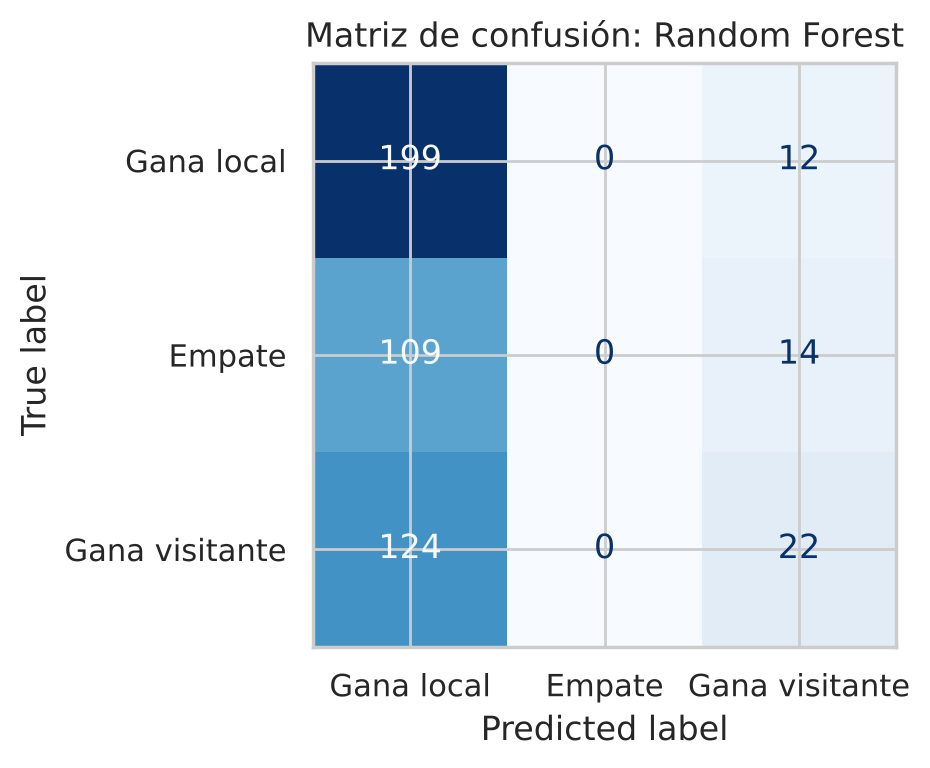

In [17]:
nombre_mejor = tabla.drop(index=[i for i in tabla.index if i.startswith("Referencia")]).index[0]
mejor = ajustados[nombre_mejor]
pred_mejor = mejor.predict(X_test)
print(f"Mejor modelo: {nombre_mejor}\n")
print(classification_report(y_test, pred_mejor, labels=CLASES,
                            target_names=[etiquetas[c] for c in CLASES]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_mejor, labels=CLASES),
                       display_labels=[etiquetas[c] for c in CLASES]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión: {nombre_mejor}")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "matriz_confusion.png", dpi=150)
plt.show()

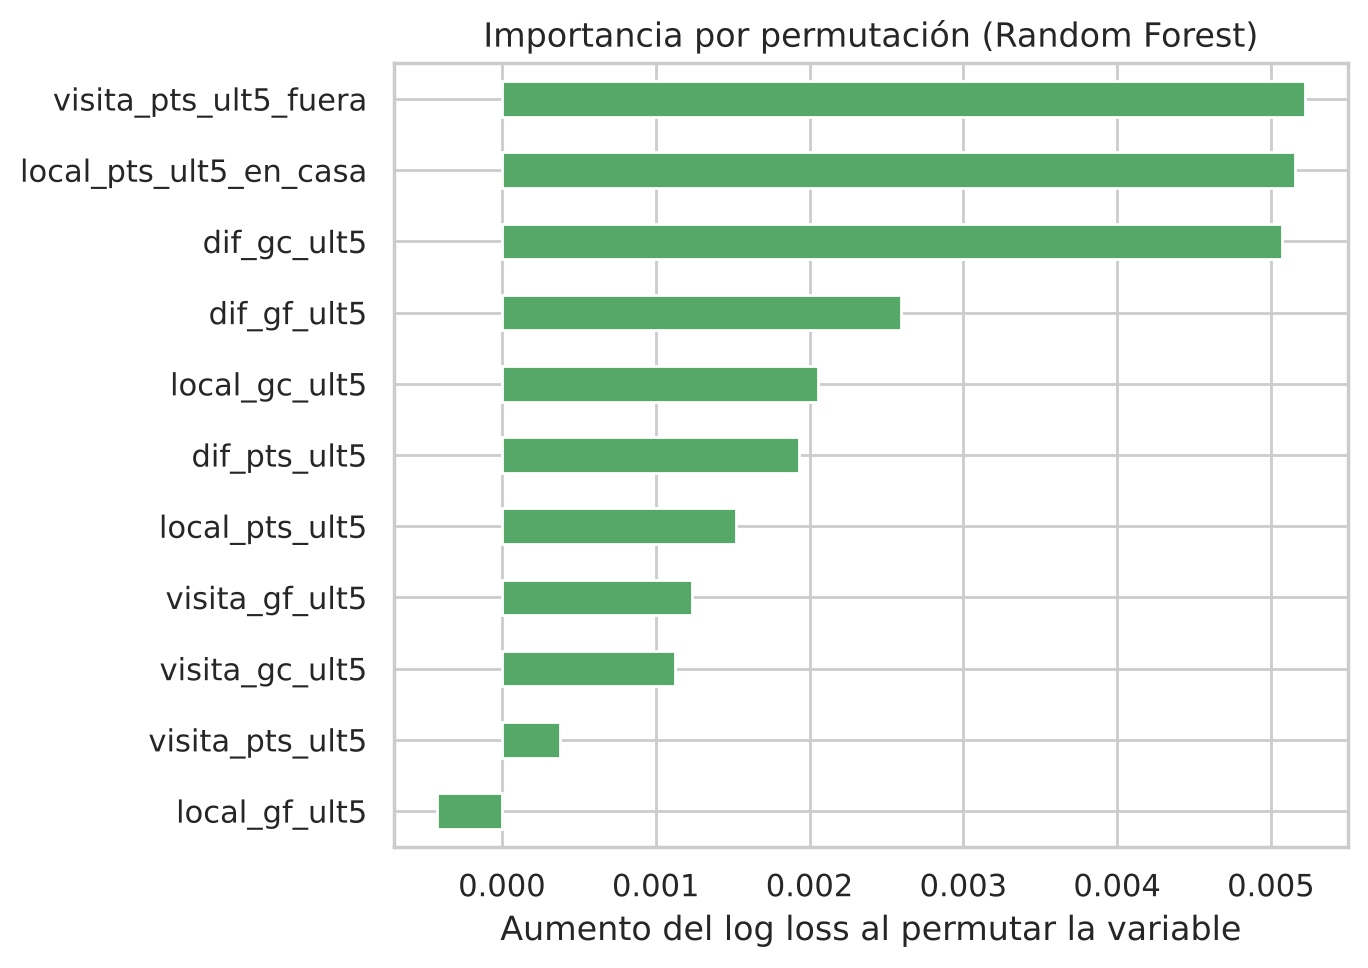

In [18]:
importancia = permutation_importance(mejor, X_test, y_test, scoring="neg_log_loss",
                                     n_repeats=20, random_state=SEMILLA)
imp = pd.Series(importancia.importances_mean, index=VARIABLES).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax, color="#55A868")
ax.set(title=f"Importancia por permutación ({nombre_mejor})",
       xlabel="Aumento del log loss al permutar la variable")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "importancia_variables.png", dpi=150)
plt.show()

## 7. Conclusiones y limitaciones

**Datos usados:** 4,799 partidos de la Liga MX (21/07/2012 a 14/11/2026). Después de descartar los partidos sin historial suficiente quedaron 4,751: 4,271 para entrenamiento (2012/2013 a 2024/2025) y 480 para prueba (2025/2026 y lo jugado de 2026/2027).

**Resultados en las temporadas de prueba**

| Modelo | Accuracy | F1 macro | Log loss |
|---|---|---|---|
| Referencia: momios de cierre | 0.510 | 0.380 | 1.001 |
| Random Forest | 0.460 | 0.282 | 1.052 |
| Regresión logística | 0.471 | 0.307 | 1.053 |
| SVM | 0.452 | 0.258 | 1.061 |
| Referencia: siempre local | 0.440 | 0.204 | 1.074 |

**Resultados principales**
- Los tres modelos superan a la referencia "siempre local" en todas las métricas. El mejor log loss fue el de **Random Forest (1.052)**, prácticamente empatado con la regresión logística (1.053), que tuvo la mejor accuracy: **47.1 %, 3.1 puntos porcentuales arriba** del 44.0 % de predecir siempre al local.
- Los momios de cierre siguen siendo claramente mejores (accuracy 51.0 % y log loss 1.001). La diferencia es esperable: el mercado incorpora alineaciones, lesiones, calendario y calidad de plantilla, mientras que este modelo solo conoce los últimos cinco resultados de cada equipo.
- Las variables más útiles fueron la **forma del visitante jugando fuera** (`visita_pts_ult5_fuera`), la **forma del local jugando en casa** (`local_pts_ult5_en_casa`) y la **diferencia de goles en contra** (`dif_gc_ult5`). Separar el rendimiento por condición aporta más que la forma general.
- Ningún modelo predice empates. Es un comportamiento común en fútbol: el empate casi nunca es el resultado más probable de un partido aunque ocurra en el 27 % de los casos, así que al elegir la clase con mayor probabilidad no aparece.

**Limitaciones**
- Solo se usan resultados históricos; no hay información de plantillas, lesiones, tiros o posesión.
- El conjunto de prueba incluye la temporada 2026/2027 incompleta (144 partidos al momento de la descarga), y en ella el porcentaje de victorias locales es inusualmente bajo (36.8 %).
- Los datos incluyen partidos de liguilla, que tienen una dinámica distinta a la fase regular.
- La Liga MX tiene torneos cortos (Apertura y Clausura) y cambios frecuentes de plantilla entre torneos, lo que reduce el valor de la forma reciente al inicio de cada torneo.

**Siguientes pasos**
- Agregar un rating tipo Elo por equipo para medir la fuerza de largo plazo y no solo la forma reciente.
- Incluir estadísticas de partido (tiros, tiros a puerta) si se consigue una fuente confiable.
- Probar modelos de boosting (XGBoost, LightGBM) y calibración de probabilidades.